# IT3091 Bank Marketing · Member 4 (IT24100001)
## Part 2: Probability Threshold Tuning and Decile Queues

Part 1 evaluated Member 3's four tuned models at the default 0.5 threshold and explained them. Part 2 turns the model scores into **decisions**:

| Step | What happens | Why it matters |
|---|---|---|
| 0 | Setup, same Drive folders as Part 1 | Reuses the same saved files |
| 1 | Load data and models, check they line up | Wrong row order would silently give wrong results |
| 2 | Leakage-safe out-of-fold (OOF) scores on the **training** set | Lets us tune without touching the test set |
| 3 | Tune the threshold for each model | 0.5 is the wrong cut-off when only ~12% subscribe |
| 4 | Choose the final model | Fair comparison: every model at its own best threshold |
| 5 | Check the tuned threshold on the test set (one look) | Honest before/after evidence for the report |
| 6 | Build the decile queue | Turns scores into a ranked calling list |
| 7 | Lift, cumulative gains and call-capacity view | The business case: how much better than random calling |
| 8 | Save outputs for Part 3 (the app) | Threshold and decile cut points are reused, never recomputed |
| 9 | File access log | Proof of which member folders were read and that only your folder was written to |

**Golden rule:** the threshold, the final model and the decile cut points are all learned from **training data only**. The test set is only used to *report* how well they work.

### Files this notebook touches

| Folder (owner) | File | Read / Write | Section | Why |
|---|---|---|---|---|
| Member 1 (`IT24102060`) | `ds52-train_test_split.joblib` | READ | 1 | Raw 15 columns and labels |
| Member 2 (`IT24101461`) | `IT24101461_selected_data.joblib` | READ | 1 | Processed 30 columns the models expect |
| Member 2 (`IT24101461`) | `IT24101461_feature_pipeline.joblib` | READ | 1 | Scaler + encoder + selector, refitted inside each fold in section 2 |
| Member 3 (`My files`) | 4 × `IT24102228_*_tuned.joblib` | READ | 1 | The tuned models |
| Member 4 (`IT24100001`) | `IT24100001_part2_oof_scores.joblib` | READ + WRITE | 2 | Cache, so re-runs are fast |
| Member 4 (`IT24100001`) | `figures/07 … 11_*.png` | WRITE | 3 to 7 | Charts for the report |
| Member 4 (`IT24100001`) | `IT24100001_test_calling_queue.csv` | WRITE | 7.4 | The ranked calling list |
| Member 4 (`IT24100001`) | `IT24100001_part2_threshold_deciles.joblib` + 3 CSVs | WRITE | 8 | Results for the report and the app |
| Member 4 (`IT24100001`) | `IT24100001_part2_file_access_log.csv` | WRITE | 9 | Record of every file read and written |

**Nothing is ever written to the Member 1, 2 or 3 folders.** Their files are only read. Every read and write prints a line starting with `[READ ]` or `[WRITE]` naming the folder, and section 9 prints the complete log.

## 0. Setup

In [1]:
import os, sys, time, warnings, subprocess
warnings.filterwarnings("ignore")

def ensure(pkg):
    try:
        return __import__(pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg])
        return __import__(pkg)

ensure("lightgbm"); ensure("xgboost")   # needed to load Member 3's boosted models

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score,
                             roc_auc_score, average_precision_score,
                             precision_recall_curve, confusion_matrix)

RANDOM_STATE = 42          # same seed as the whole team, so folds match Member 3
np.random.seed(RANDOM_STATE)
sns.set_style("whitegrid")
pd.set_option("display.width", 160)
print("scikit-learn:", sklearn.__version__)

scikit-learn: 1.6.1


### Folder of each member
**Edit the four folder names below if your files are somewhere else.** Each file is looked for first in the folder of the member who made it. If it is not there, the other folders are checked, and a `NOTE` line tells you exactly where it was found instead (for example, Member 3 copied Member 1's and Member 2's files into `My files`).

In [2]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass  # running outside Colab

PROJECT_DIR = os.environ.get("M4_PROJECT_DIR",
                             "/content/drive/MyDrive/ML & DWBI Assignment/ML Assignment")

# ---- one folder per member: CHANGE HERE if needed -----------------------------------
FOLDERS = {
    "Member 1": os.path.join(PROJECT_DIR, "IT24102060"),   # train/test split (READ only)
    "Member 2": os.path.join(PROJECT_DIR, "IT24101461"),   # feature engineering (READ only)
    "Member 3": os.path.join(PROJECT_DIR, "IT24102228"),     # tuned models (READ only)
    "Member 4": os.path.join(PROJECT_DIR, "IT24100001"),   # YOU: every output is written here
}
MEMBER_4_DIR = FOLDERS["Member 4"]
FIG_DIR = os.path.join(MEMBER_4_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

ACCESS_LOG = []   # every read and write is recorded here and printed in section 9

def short(p):
    return os.path.relpath(p, PROJECT_DIR)

def locate(owner, filename):
    # Look in the owner's folder first, then in the other members' folders
    expected = os.path.join(FOLDERS[owner], filename)
    if os.path.exists(expected):
        return expected, owner
    for other, folder in FOLDERS.items():
        candidate = os.path.join(folder, filename)
        if other != owner and os.path.exists(candidate):
            return candidate, other
    raise FileNotFoundError(f"{filename} ({owner}'s file) not found in any member folder: "
                            f"{list(FOLDERS.values())}")

def read_file(owner, filename, why):
    # Load a joblib file made by `owner`, print where it came from, and log it
    full, found_in = locate(owner, filename)
    if found_in != owner:
        print(f"NOTE  {filename} is not in the {owner} folder; using the copy in the {found_in} folder")
    print(f"[READ ] {found_in} folder -> {short(full)}   ({why})")
    ACCESS_LOG.append({"action": "READ", "file owner": owner, "folder used": found_in,
                       "path": short(full), "purpose": why})
    return joblib.load(full)

def log_write(full, why):
    print(f"[WRITE] Member 4 folder -> {short(full)}   ({why})")
    ACCESS_LOG.append({"action": "WRITE", "file owner": "Member 4", "folder used": "Member 4",
                       "path": short(full), "purpose": why})

def save_fig(name):
    full = os.path.join(FIG_DIR, name)
    plt.savefig(full, dpi=150, bbox_inches="tight")
    log_write(full, "figure for the report")

for owner, folder in FOLDERS.items():
    print(f"{owner}: {folder}  {'(exists)' if os.path.isdir(folder) else '(FOLDER NOT FOUND)'}")

Mounted at /content/drive
Member 1: /content/drive/MyDrive/ML & DWBI Assignment/ML Assignment/IT24102060  (exists)
Member 2: /content/drive/MyDrive/ML & DWBI Assignment/ML Assignment/IT24101461  (exists)
Member 3: /content/drive/MyDrive/ML & DWBI Assignment/ML Assignment/IT24102228  (exists)
Member 4: /content/drive/MyDrive/ML & DWBI Assignment/ML Assignment/IT24100001  (exists)


### Pre-flight check
Before loading anything, confirm every required file can be found, and in which member's folder. No file is opened yet.

In [3]:
MODEL_FILES = {
    "Logistic Regression": "IT24102228_logistic_regression_tuned.joblib",
    "Random Forest":       "IT24102228_random_forest_tuned.joblib",
    "XGBoost":             "IT24102228_xgboost_tuned.joblib",
    "LightGBM":            "IT24102228_lightgbm_tuned.joblib",
}
REQUIRED = [("Member 1", "ds52-train_test_split.joblib"),
            ("Member 2", "IT24101461_selected_data.joblib"),
            ("Member 2", "IT24101461_feature_pipeline.joblib")] + \
           [("Member 3", f) for f in MODEL_FILES.values()]

rows = []
for owner, f in REQUIRED:
    try:
        full, found_in = locate(owner, f)
        rows.append({"made by": owner, "file": f, "found in": f"{found_in} folder",
                     "status": "OK" if found_in == owner else "OK (copy)"})
    except FileNotFoundError:
        rows.append({"made by": owner, "file": f, "found in": "-", "status": "MISSING"})
preflight = pd.DataFrame(rows)
assert (preflight["status"] != "MISSING").all(), "A required file is missing: see the table."
preflight

,made by,file,found in,status
0,Member 1,ds52-train_test_split.joblib,Member 1 folder,OK
1,Member 2,IT24101461_selected_data.joblib,Member 2 folder,OK
2,Member 2,IT24101461_feature_pipeline.joblib,Member 2 folder,OK
3,Member 3,IT24102228_logistic_regression_tuned.joblib,Member 3 folder,OK
4,Member 3,IT24102228_random_forest_tuned.joblib,Member 3 folder,OK
5,Member 3,IT24102228_xgboost_tuned.joblib,Member 3 folder,OK
6,Member 3,IT24102228_lightgbm_tuned.joblib,Member 3 folder,OK


## 1. Load data and models

We need two versions of the same customers:

| Version | Columns | Used for |
|---|---|---|
| Raw (Member 1) | 15 original columns | Leakage-safe OOF in step 2, and the readable calling queue in step 6 |
| Processed (Member 2) | 30 selected columns | Scoring the test set with Member 3's models |

**File access in this cell:** READ from the **Member 1**, **Member 2** and **Member 3** folders. These are the only times Part 2 opens another member's files.

In [4]:
# >>> MEMBER 1 FOLDER: raw split (15 original columns, 'duration' already removed)
X_train_raw, X_test_raw, y_train_raw, y_test_raw = read_file(
    "Member 1", "ds52-train_test_split.joblib", "raw customers and labels")

# >>> MEMBER 2 FOLDER: processed 30-column data, and the fitted feature pipeline
X_train, X_test, y_train_s, y_test_s, selected_names = read_file(
    "Member 2", "IT24101461_selected_data.joblib", "30 processed columns for scoring")
feature_pipeline = read_file(
    "Member 2", "IT24101461_feature_pipeline.joblib", "scaler + encoder + selector")

# >>> MEMBER 3 FOLDER: the four tuned models
models = {name: read_file("Member 3", f, f"tuned {name}") for name, f in MODEL_FILES.items()}

# Targets may be stored as "yes"/"no" or 1/0: convert everything to 1/0
def to01(y):
    y = pd.Series(y)
    return (y if pd.api.types.is_numeric_dtype(y) else y.map({"no": 0, "yes": 1})).astype(int).to_numpy()
y_train, y_test = to01(y_train_s), to01(y_test_s)

# WHY: the raw and processed files come from different members. If the rows were not
# in the same order, every result below would be wrong without any error message.
checks = {
    "same number of training rows (raw vs processed)": len(X_train_raw) == len(X_train),
    "same number of test rows (raw vs processed)":     len(X_test_raw) == len(X_test),
    "training labels identical (Member 1 vs Member 2)": np.array_equal(to01(y_train_raw), y_train),
    "test labels identical (Member 1 vs Member 2)":     np.array_equal(to01(y_test_raw), y_test),
    "'duration' is not a feature (leakage removed)":    "duration" not in X_train_raw.columns,
}
for k, v in checks.items():
    print(("PASS " if v else "FAIL ") + k)
assert all(checks.values()), "Fix the failed check before continuing."

BASE_RATE = y_train.mean()
print(f"\nTrain {len(y_train):,} | Test {len(y_test):,} | subscription rate {BASE_RATE:.2%}")

[READ ] Member 1 folder -> IT24102060/ds52-train_test_split.joblib   (raw customers and labels)
[READ ] Member 2 folder -> IT24101461/IT24101461_selected_data.joblib   (30 processed columns for scoring)
[READ ] Member 2 folder -> IT24101461/IT24101461_feature_pipeline.joblib   (scaler + encoder + selector)
[READ ] Member 3 folder -> IT24102228/IT24102228_logistic_regression_tuned.joblib   (tuned Logistic Regression)
[READ ] Member 3 folder -> IT24102228/IT24102228_random_forest_tuned.joblib   (tuned Random Forest)
[READ ] Member 3 folder -> IT24102228/IT24102228_xgboost_tuned.joblib   (tuned XGBoost)
[READ ] Member 3 folder -> IT24102228/IT24102228_lightgbm_tuned.joblib   (tuned LightGBM)
PASS same number of training rows (raw vs processed)
PASS same number of test rows (raw vs processed)
PASS training labels identical (Member 1 vs Member 2)
PASS test labels identical (Member 1 vs Member 2)
PASS 'duration' is not a feature (leakage removed)

Train 36,168 | Test 9,043 | subscription rat

### Member 2's feature engineering, as one function
Step 2 refits the whole chain inside every fold, starting from raw data, so it needs Member 2's feature engineering as a single reusable function. The rules below are copied exactly from Member 2's notebook (sections 1.3 to 1.9). They are fixed rules, nothing is learned from data, so the function cannot leak information.

The check underneath confirms it gives exactly the same 30 test columns as Member 2's saved data.

**File access:** none. It reuses the Member 1 and Member 2 data already loaded above.

In [5]:
def engineer_features(df):
    out = df.copy()
    out = out.drop(columns=[c for c in ["duration", "y"] if c in out.columns])
    out["previously_contacted"] = (out["pdays"] != -1).astype(int)            # 1.3
    out["pdays_clean"] = out["pdays"].replace(-1, 0)                          # 1.4
    out["loan_count"] = ((out["housing"] == "yes").astype(int)                # 1.5
                         + (out["loan"] == "yes").astype(int))
    out["has_credit_default"] = (out["default"] == "yes").astype(int)
    out["previous_campaign_success"] = (out["poutcome"] == "success").astype(int)  # 1.6
    out["age_group"] = pd.cut(out["age"], bins=[17, 30, 40, 50, 60, np.inf],       # 1.7
                              labels=["18-30", "31-40", "41-50", "51-60", "60+"])
    out["balance_group"] = pd.cut(out["balance"], bins=[-np.inf, -1, 0, 1000, 5000, np.inf],  # 1.8
                                  labels=["negative", "zero", "low", "medium", "high"])
    out["campaign_contact_group"] = pd.cut(out["campaign"], bins=[0, 1, 2, 4, np.inf],         # 1.9
                                           labels=["first_contact", "second_contact",
                                                   "three_to_four", "five_or_more"])
    return out

# Compatibility fix Member 3 also needed: the pipeline was saved with a different scikit-learn version
def repair(obj):
    if isinstance(obj, ColumnTransformer) and getattr(obj, "force_int_remainder_cols", None) == "deprecated":
        obj.force_int_remainder_cols = False
    for _, child in getattr(obj, "steps", []):
        repair(child)
    for t in getattr(obj, "transformers", []):
        if t[1] not in ("drop", "passthrough"):
            repair(t[1])
repair(feature_pipeline)

reproduced = feature_pipeline.transform(engineer_features(X_test_raw))
ENGINEERING_OK = reproduced.shape == np.asarray(X_test).shape and np.allclose(reproduced, X_test)
print("PASS" if ENGINEERING_OK else "FAIL",
      "engineer_features + Member 2 pipeline reproduce the 30 processed test columns")

PASS engineer_features + Member 2 pipeline reproduce the 30 processed test columns


## 2. Out-of-fold (OOF) scores on the training set

**Problem:** we want to tune the threshold, but tuning on the test set would make the test result dishonest. Tuning on training predictions is also wrong, because the model has already seen those customers and is over-confident on them.

**Solution: out-of-fold predictions.** Split the training set into 5 parts. Train on 4, score the 5th, and repeat until every training customer has a score from a model that **never saw them**. These scores behave like test scores, but we are allowed to tune on them.

**Leakage-safe:** Member 2 fitted the scaler and SelectKBest on the whole training set, so Member 3's cross-validation used columns chosen with knowledge of every fold. Here, each fold refits the **whole chain from raw data**:

`engineer_features` → impute + scale + one-hot → SelectKBest (30) → model with Member 3's tuned settings

Same folds as Member 3: `StratifiedKFold(5, shuffle=True, random_state=42)`. The first run can take several minutes (Random Forest is the slowest).

**File access:** READ + WRITE the cache `IT24100001_part2_oof_scores.joblib` in the **Member 4** folder only. No other member's folder is touched: the fold copies are built from data already in memory.

In [6]:
LEAKAGE_SAFE = ENGINEERING_OK      # falls back to Member 2's processed arrays only if the check failed
FORCE_RECOMPUTE = False            # set True to ignore the cache and recompute
OOF_CACHE = os.path.join(MEMBER_4_DIR, "IT24100001_part2_oof_scores.joblib")
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def classifier_of(model):
    # Member 3 saved each model as Pipeline([("classifier", ...)]): take the classifier itself
    return model.named_steps["classifier"] if hasattr(model, "named_steps") else model

def full_chain(model):
    # A fresh, unfitted copy of the raw-to-prediction chain with Member 3's tuned settings
    return Pipeline([("engineer", FunctionTransformer(engineer_features)),
                     ("features", clone(feature_pipeline)),
                     ("model", clone(classifier_of(model)))])

mode = "leakage_safe" if LEAKAGE_SAFE else "preselected_arrays"
oof = {}
if os.path.exists(OOF_CACHE) and not FORCE_RECOMPUTE:
    # >>> MEMBER 4 FOLDER: read the cache from an earlier run
    cached = read_file("Member 4", os.path.basename(OOF_CACHE), "cached OOF scores")
    if cached.get("n_train") == len(y_train) and cached.get("mode") == mode:
        oof = cached["oof"]
        print("Using cached OOF scores")

print("OOF mode:", mode)
for name, model in models.items():
    if name in oof:
        continue
    t0 = time.time()
    estimator, X_cv = (full_chain(model), X_train_raw) if LEAKAGE_SAFE else (clone(model), X_train)
    oof[name] = cross_val_predict(estimator, X_cv, y_train, cv=skf,
                                  method="predict_proba", n_jobs=-1)[:, 1]
    print(f"{name:<20} done in {time.time() - t0:.0f}s")
    # >>> MEMBER 4 FOLDER: save the cache after each model, so a crash loses little work
    joblib.dump({"oof": oof, "n_train": len(y_train), "mode": mode}, OOF_CACHE)
    log_write(OOF_CACHE, f"OOF cache after {name}")

pd.DataFrame({name: {"OOF ROC-AUC": roc_auc_score(y_train, p),
                     "OOF PR-AUC": average_precision_score(y_train, p)}
              for name, p in oof.items()}).T.round(4)

OOF mode: leakage_safe
Logistic Regression  done in 73s
[WRITE] Member 4 folder -> IT24100001/IT24100001_part2_oof_scores.joblib   (OOF cache after Logistic Regression)
Random Forest        done in 91s
[WRITE] Member 4 folder -> IT24100001/IT24100001_part2_oof_scores.joblib   (OOF cache after Random Forest)
XGBoost              done in 64s
[WRITE] Member 4 folder -> IT24100001/IT24100001_part2_oof_scores.joblib   (OOF cache after XGBoost)
LightGBM             done in 64s
[WRITE] Member 4 folder -> IT24100001/IT24100001_part2_oof_scores.joblib   (OOF cache after LightGBM)


,OOF ROC-AUC,OOF PR-AUC
Logistic Regression,0.7600,0.3845
Random Forest,0.7633,0.3938
XGBoost,0.7836,0.4246
LightGBM,0.7738,0.4144


These OOF ranking scores should be close to, or slightly below, Member 3's cross-validation scores. Slightly lower is expected: feature selection no longer gets to peek at the validation folds.

## 3. Threshold tuning

The model gives every customer a **score** between 0 and 1. The **threshold** turns it into a decision: score ≥ threshold → "call", otherwise "don't call".

**Why not 0.5?** Only about 12% of customers subscribe. Models trained with class weighting push scores up, models without it (XGBoost) keep them low. Either way, 0.5 is an arbitrary cut-off that has nothing to do with this dataset.

**How we tune:** try every possible threshold on the OOF scores, and keep the one with the highest **F1**, the report's primary metric. F1 balances:

| Lower threshold | Higher threshold |
|---|---|
| More customers called | Fewer customers called |
| Higher **recall** (miss fewer subscribers) | Higher **precision** (fewer wasted calls) |

In [7]:
def best_f1_threshold(y, scores):
    # precision_recall_curve tests every distinct score as a threshold
    prec, rec, thr = precision_recall_curve(y, scores)
    prec, rec = prec[:-1], rec[:-1]                     # last point has no threshold
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    i = int(np.nanargmax(f1))
    return {"threshold": float(thr[i]), "f1": float(f1[i]),
            "precision": float(prec[i]), "recall": float(rec[i]),
            "curve": pd.DataFrame({"threshold": thr, "precision": prec, "recall": rec, "f1": f1})}

tuned, rows = {}, []
for name, s in oof.items():
    t = best_f1_threshold(y_train, s)
    tuned[name] = t
    rows.append({"Model": name,
                 "OOF F1 @0.5": f1_score(y_train, (s >= 0.5).astype(int)),
                 "Best threshold": t["threshold"],
                 "OOF F1 @best": t["f1"],
                 "Precision @best": t["precision"],
                 "Recall @best": t["recall"],
                 "% customers called": (s >= t["threshold"]).mean() * 100,
                 "OOF PR-AUC": average_precision_score(y_train, s)})
threshold_table = pd.DataFrame(rows).set_index("Model").sort_values("OOF F1 @best", ascending=False)
threshold_table.round(4)

,OOF F1 @0.5,Best threshold,OOF F1 @best,Precision @best,Recall @best,% customers called,OOF PR-AUC
Model,,,,,,,
XGBoost,0.3299,0.2033,0.4510,0.4284,0.4762,13.0060,0.4246
LightGBM,0.4131,0.6506,0.4381,0.4399,0.4363,11.6014,0.4144
Logistic Regression,0.3657,0.6444,0.4193,0.4376,0.4025,10.7609,0.3845
Random Forest,0.4115,0.4538,0.4152,0.3811,0.4559,13.9958,0.3938


[WRITE] Member 4 folder -> IT24100001/figures/07_threshold_f1_all_models.png   (figure for the report)


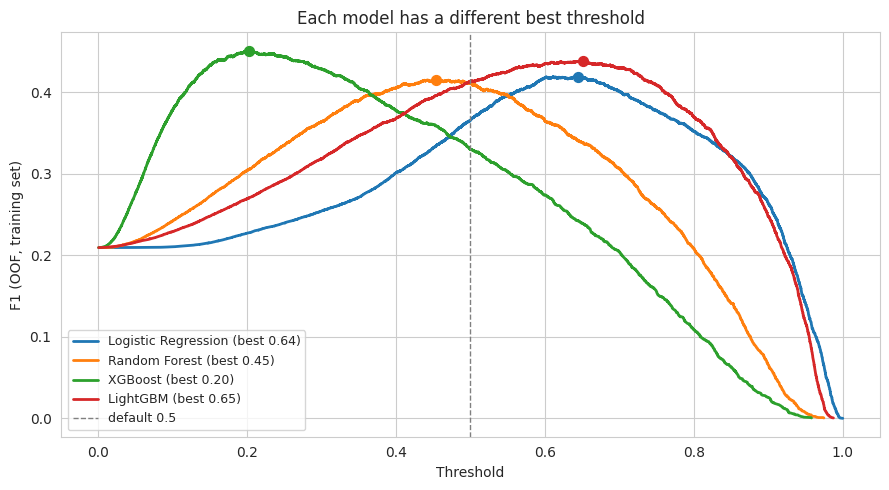

In [8]:
# F1 against threshold for every model: the dot marks each model's best cut-off
plt.figure(figsize=(9, 5))
for name, t in tuned.items():
    c = t["curve"]
    plt.plot(c["threshold"], c["f1"], lw=2, label=f"{name} (best {t['threshold']:.2f})")
    plt.scatter([t["threshold"]], [t["f1"]], s=50, zorder=3)
plt.axvline(0.5, color="grey", ls="--", lw=1, label="default 0.5")
plt.xlabel("Threshold"); plt.ylabel("F1 (OOF, training set)")
plt.title("Each model has a different best threshold")
plt.legend(fontsize=9); plt.tight_layout(); save_fig("07_threshold_f1_all_models.png"); plt.show()

**Reading it:** a model whose best point is far from the dashed line was judged unfairly at 0.5 in Member 3's comparison. XGBoost, which has no class weighting, usually wants a much lower threshold. Class-weighted models usually want a higher one.

## 4. Choose the final model

Rule: the highest **OOF F1 at its own tuned threshold**. This is a fair comparison (every model gets its best cut-off) and it uses training data only.

If the team agrees to keep Member 3's choice instead, set `FINAL_MODEL_OVERRIDE = "Random Forest"` and say so in the report. Then use **Runtime → Run after** from this cell; the OOF scores are cached, so it is quick.

In [9]:
FINAL_MODEL_OVERRIDE = None        # e.g. "Random Forest"

FINAL_MODEL = FINAL_MODEL_OVERRIDE or threshold_table["OOF F1 @best"].idxmax()
THRESHOLD = tuned[FINAL_MODEL]["threshold"]
final_model = models[FINAL_MODEL]
oof_final = oof[FINAL_MODEL]

print(f"Final model : {FINAL_MODEL}"
      + ("  (team override)" if FINAL_MODEL_OVERRIDE else "  (highest OOF F1 at tuned threshold)"))
print(f"Threshold   : {THRESHOLD:.4f}   (chosen on training OOF scores only)")
print(f"At this threshold the model calls {(oof_final >= THRESHOLD).mean():.1%} of customers")

Final model : XGBoost  (highest OOF F1 at tuned threshold)
Threshold   : 0.2033   (chosen on training OOF scores only)
At this threshold the model calls 13.0% of customers


[WRITE] Member 4 folder -> IT24100001/figures/08_threshold_tradeoff_final.png   (figure for the report)


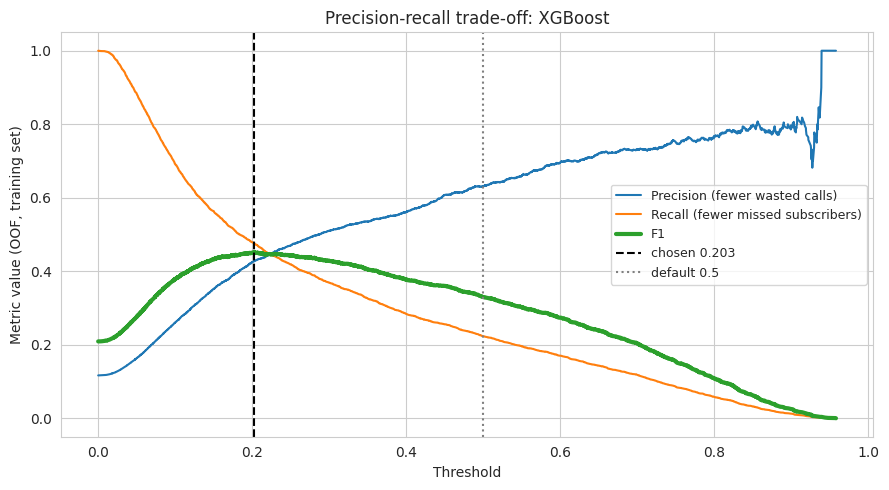

In [10]:
# Precision, recall and F1 of the final model as the threshold moves
c = tuned[FINAL_MODEL]["curve"]
plt.figure(figsize=(9, 5))
plt.plot(c["threshold"], c["precision"], label="Precision (fewer wasted calls)")
plt.plot(c["threshold"], c["recall"], label="Recall (fewer missed subscribers)")
plt.plot(c["threshold"], c["f1"], lw=3, label="F1")
plt.axvline(THRESHOLD, color="black", ls="--", lw=1.5, label=f"chosen {THRESHOLD:.3f}")
plt.axvline(0.5, color="grey", ls=":", lw=1.5, label="default 0.5")
plt.xlabel("Threshold"); plt.ylabel("Metric value (OOF, training set)")
plt.title(f"Precision-recall trade-off: {FINAL_MODEL}")
plt.legend(fontsize=9); plt.tight_layout(); save_fig("08_threshold_tradeoff_final.png"); plt.show()

**The trade-off in one sentence:** moving the threshold left catches more subscribers but wastes more calls; moving it right does the opposite. F1 picks the balance point.

### Capacity-based thresholds
F1 is not the only sensible choice. If the call centre can only make a fixed number of calls, the threshold should be "whatever score the top N% of customers reach". The table shows what each option would deliver (OOF, training set).

In [11]:
rows = []
for share in [0.05, 0.10, 0.20, 0.30]:
    t = float(np.quantile(oof_final, 1 - share))     # score reached by the top `share` of customers
    pred = (oof_final >= t).astype(int)
    rows.append({"Call budget": f"top {int(share * 100)}%", "Threshold": t,
                 "Precision": precision_score(y_train, pred, zero_division=0),
                 "Recall": recall_score(y_train, pred), "F1": f1_score(y_train, pred)})
pred = (oof_final >= THRESHOLD).astype(int)
rows.append({"Call budget": f"F1-optimal ({pred.mean():.0%} called)", "Threshold": THRESHOLD,
             "Precision": precision_score(y_train, pred), "Recall": recall_score(y_train, pred),
             "F1": f1_score(y_train, pred)})
capacity_thresholds = pd.DataFrame(rows).set_index("Call budget")
capacity_thresholds.round(4)

,Threshold,Precision,Recall,F1
Call budget,,,,
top 5%,0.4470,0.6025,0.2576,0.3609
top 10%,0.2586,0.4775,0.4082,0.4401
top 20%,0.1425,0.3383,0.5784,0.4269
top 30%,0.1036,0.2662,0.6828,0.3831
F1-optimal (13% called),0.2033,0.4284,0.4762,0.4510


## 5. Does the tuned threshold hold up on the test set?

This is the **only** time Part 2 looks at the test set. Nothing below changes any choice made above.

**File access:** none for data. The test set was already loaded from the Member 2 folder in section 1. One figure is written to the Member 4 folder. It gives the honest before/after numbers for the report: same models, default 0.5 vs the threshold tuned on training data.

In [12]:
test_scores = {name: m.predict_proba(X_test)[:, 1] for name, m in models.items()}

rows = []
for name, s in test_scores.items():
    for label, t in [("0.5", 0.5), ("tuned", tuned[name]["threshold"])]:
        pred = (s >= t).astype(int)
        rows.append({"Model": name, "Threshold": label, "Value": round(t, 3),
                     "Precision": precision_score(y_test, pred, zero_division=0),
                     "Recall": recall_score(y_test, pred),
                     "F1": f1_score(y_test, pred),
                     "Accuracy": accuracy_score(y_test, pred),
                     "Customers called": int(pred.sum())})
test_threshold_table = pd.DataFrame(rows).set_index(["Model", "Threshold"])
test_threshold_table.round(4)

Value  Precision  Recall      F1  Accuracy  Customers called
Model               Threshold                                                              
Logistic Regression 0.5        0.500     0.2599  0.6446  0.3705    0.7437              2624
                    tuned      0.644     0.4490  0.4074  0.4272    0.8722               960
Random Forest       0.5        0.500     0.4504  0.4206  0.4350    0.8722               988
                    tuned      0.454     0.3998  0.4792  0.4359    0.8549              1268
XGBoost             0.5        0.500     0.6490  0.2202  0.3289    0.8948               359
                    tuned      0.203     0.4504  0.4802  0.4648    0.8706              1128
LightGBM            0.5        0.500     0.3298  0.5964  0.4248    0.8110              1913
                    tuned      0.651     0.4566  0.4527  0.4547    0.8729              1049

[WRITE] Member 4 folder -> IT24100001/figures/09_threshold_before_after_test.png   (figure for the report)


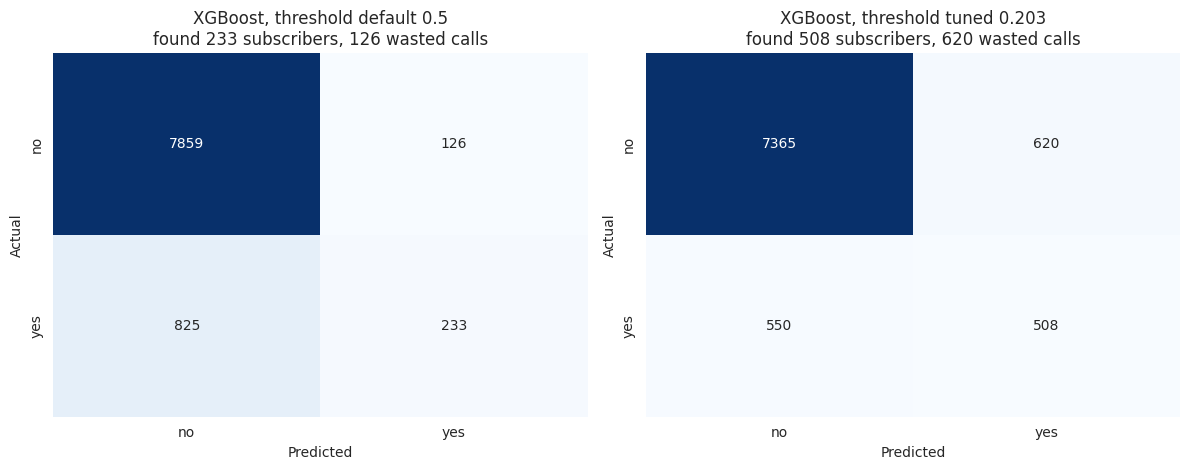

Test F1 for XGBoost: 0.3289 at 0.5  ->  0.4648 at the tuned threshold


In [13]:
s_final = test_scores[FINAL_MODEL]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (label, t) in zip(axes, [("default 0.5", 0.5), (f"tuned {THRESHOLD:.3f}", THRESHOLD)]):
    cm = confusion_matrix(y_test, (s_final >= t).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["no", "yes"], yticklabels=["no", "yes"])
    tn, fp, fn, tp = cm.ravel()
    ax.set(title=f"{FINAL_MODEL}, threshold {label}\nfound {tp} subscribers, {fp} wasted calls",
           xlabel="Predicted", ylabel="Actual")
plt.tight_layout(); save_fig("09_threshold_before_after_test.png"); plt.show()

f05 = f1_score(y_test, (s_final >= 0.5).astype(int))
ftu = f1_score(y_test, (s_final >= THRESHOLD).astype(int))
print(f"Test F1 for {FINAL_MODEL}: {f05:.4f} at 0.5  ->  {ftu:.4f} at the tuned threshold")

**If the tuned F1 is close to the OOF F1 from step 3**, the threshold generalises: it was not over-fitted to the training data. That is the evidence to quote in the report.

## 6. The decile queue

A yes/no flag is useful, but a call centre works through a **list**. The decile queue sorts customers by score and cuts them into 10 equal groups:

* **Decile 1** = the 10% of customers most likely to subscribe → call first
* **Decile 10** = the 10% least likely → lower-cost channel, or skip

**Where the cut points come from:** the 9 score boundaries between deciles are taken from the **training OOF scores**, not the test set. That is exactly how a brand-new customer will be placed into a decile in the app. We then check that test customers fall into the deciles in roughly equal 10% shares.

**Expected conversion rate per decile:** from the training OOF scores we also record how often customers in each decile actually subscribed. This is a more honest number to show a manager than the raw model score, which class weighting inflates (Part 1, calibration chart).

In [14]:
def assign_decile(scores, edges):
    # Decile 1 = highest scores, 10 = lowest. `edges` are 9 ascending cut points.
    return 10 - np.searchsorted(np.asarray(edges), np.asarray(scores), side="right")

DECILE_EDGES = np.quantile(oof_final, np.linspace(0.1, 0.9, 9))   # learned on training data
if len(np.unique(DECILE_EDGES)) < 9:
    print("Note: some cut points are tied (many identical scores), so some deciles are uneven.")

train_deciles = assign_decile(oof_final, DECILE_EDGES)
DECILE_EXPECTED_RATE = (pd.Series(y_train).groupby(train_deciles).mean()
                        .reindex(range(1, 11)).to_dict())         # historical rate per decile

test_dec = pd.DataFrame({"y": y_test, "score": s_final,
                         "decile": assign_decile(s_final, DECILE_EDGES)})
print("Share of test customers per decile (should all be close to 10%):")
print((test_dec["decile"].value_counts(normalize=True).sort_index() * 100).round(1).to_string())

Share of test customers per decile (should all be close to 10%):
decile
1      9.6
2     10.7
3     10.4
4      9.9
5     10.1
6      9.7
7      9.2
8     10.1
9      9.6
10    10.7


In [15]:
overall_rate = y_test.mean()
deciles = (test_dec.groupby("decile")
           .agg(customers=("y", "size"), subscribers=("y", "sum"),
                conversion_rate=("y", "mean"), min_score=("score", "min"))
           .reindex(range(1, 11), fill_value=0))
deciles["expected_rate (train)"] = pd.Series(DECILE_EXPECTED_RATE)
deciles["lift"] = deciles["conversion_rate"] / overall_rate
deciles["cum_customers_%"] = deciles["customers"].cumsum() / deciles["customers"].sum() * 100
deciles["cum_subscribers_%"] = deciles["subscribers"].cumsum() / deciles["subscribers"].sum() * 100
deciles.index.name = "decile"
deciles.round(3)

,customers,subscribers,conversion_rate,min_score,expected_rate (train),lift,cum_customers_%,cum_subscribers_%
decile,,,,,,,,
1,869,432,0.497,0.259,0.477,4.249,9.610,40.832
2,970,186,0.192,0.143,0.199,1.639,20.336,58.412
3,942,127,0.135,0.104,0.122,1.152,30.753,70.416
4,896,71,0.079,0.081,0.092,0.677,40.661,77.127
5,913,58,0.064,0.066,0.071,0.543,50.757,82.609
6,873,48,0.055,0.054,0.054,0.470,60.411,87.146
7,834,39,0.047,0.043,0.049,0.400,69.634,90.832
8,910,38,0.042,0.034,0.041,0.357,79.697,94.423
9,864,34,0.039,0.024,0.035,0.336,89.251,97.637


| Column | Meaning |
|---|---|
| `conversion_rate` | Share of customers in that decile who actually subscribed (test set) |
| `expected_rate (train)` | The same rate measured on training OOF scores. If the two columns are close, the queue is stable on new customers |
| `lift` | Conversion rate ÷ overall rate. **Lift 3 = three times better than calling at random** |
| `cum_subscribers_%` | Share of **all** subscribers reached by calling deciles 1 to this one |

## 7. Lift, cumulative gains and call capacity

### 7.1 Lift chart
Every bar above 1 means that decile beats random calling. A good queue has tall bars on the left that fall steadily to the right.

[WRITE] Member 4 folder -> IT24100001/figures/10_decile_lift.png   (figure for the report)


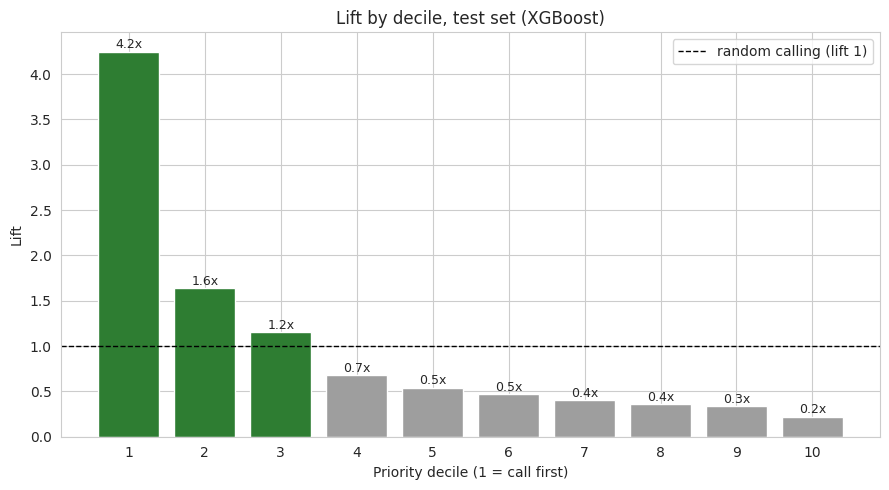

In [16]:
plt.figure(figsize=(9, 5))
colors = ["#2E7D32" if d <= 3 else "#9E9E9E" for d in deciles.index]
plt.bar(deciles.index, deciles["lift"], color=colors)
plt.axhline(1, color="black", ls="--", lw=1, label="random calling (lift 1)")
for d, v in deciles["lift"].items():
    plt.text(d, v + 0.04, f"{v:.1f}x", ha="center", fontsize=9)
plt.xticks(deciles.index)
plt.xlabel("Priority decile (1 = call first)"); plt.ylabel("Lift")
plt.title(f"Lift by decile, test set ({FINAL_MODEL})"); plt.legend()
plt.tight_layout(); save_fig("10_decile_lift.png"); plt.show()

### 7.2 Cumulative gains chart
The curve shows what share of all subscribers you reach as you work down the queue. The diagonal is random calling: call 30% of customers, reach 30% of subscribers. **The gap between the curve and the diagonal is the value of the model.**

[WRITE] Member 4 folder -> IT24100001/figures/11_cumulative_gains.png   (figure for the report)


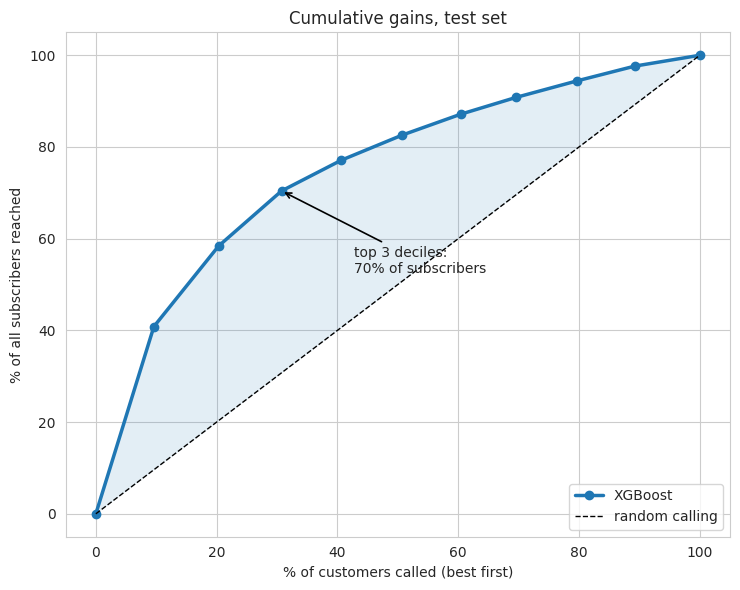

HEADLINE: calling the top 3 deciles (31% of customers) reaches 70.4% of all subscribers, against 31% for random calling.


In [17]:
x = np.r_[0, deciles["cum_customers_%"].values]
y = np.r_[0, deciles["cum_subscribers_%"].values]
plt.figure(figsize=(7.5, 6))
plt.plot(x, y, "o-", lw=2.5, label=FINAL_MODEL)
plt.plot([0, 100], [0, 100], "k--", lw=1, label="random calling")
plt.fill_between(x, x, y, alpha=0.12)
top3_cust, top3_subs = deciles.loc[3, "cum_customers_%"], deciles.loc[3, "cum_subscribers_%"]
plt.annotate(f"top 3 deciles:\n{top3_subs:.0f}% of subscribers", (top3_cust, top3_subs),
             xytext=(top3_cust + 12, top3_subs - 18), arrowprops=dict(arrowstyle="->", color="black", lw=1.2))
plt.xlabel("% of customers called (best first)"); plt.ylabel("% of all subscribers reached")
plt.title("Cumulative gains, test set"); plt.legend(loc="lower right")
plt.tight_layout(); save_fig("11_cumulative_gains.png"); plt.show()

print(f"HEADLINE: calling the top 3 deciles ({top3_cust:.0f}% of customers) reaches "
      f"{top3_subs:.1f}% of all subscribers, against {top3_cust:.0f}% for random calling.")

### 7.3 Call-capacity view
The question a marketing manager actually asks: *"We can make N calls this week. What do we get?"*

In [18]:
order = np.argsort(-s_final)                        # best customers first
rows = []
for share in [0.05, 0.10, 0.20, 0.30, 0.50]:
    n = int(round(share * len(order)))
    reached = int(y_test[order[:n]].sum())
    rows.append({"Call budget": f"top {int(share * 100)}%", "Calls": n,
                 "Subscribers reached": reached,
                 "Hit rate": reached / n,
                 "Random-calling hit rate": overall_rate,
                 "Share of all subscribers": reached / y_test.sum()})
capacity_table = pd.DataFrame(rows).set_index("Call budget")
capacity_table.round(3)

,Calls,Subscribers reached,Hit rate,Random-calling hit rate,Share of all subscribers
Call budget,,,,,
top 5%,452,279,0.617,0.117,0.264
top 10%,904,448,0.496,0.117,0.423
top 20%,1809,612,0.338,0.117,0.578
top 30%,2713,730,0.269,0.117,0.690
top 50%,4522,870,0.192,0.117,0.822


**Hit rate vs random hit rate** is the efficiency gain: how many more subscribers each call produces when the team follows the queue instead of calling at random.

### 7.4 The calling queue itself
This is the actual output for the call centre: every test customer, ranked, with their decile and the call decision. It is saved as a CSV so it can be opened in Excel.

**File access:** customer details come from Member 1's raw test data, already in memory. The CSV is written to the **Member 4** folder.

In [19]:
queue = X_test_raw.reset_index(drop=True).copy()
queue.insert(0, "score", s_final)
queue.insert(1, "priority_decile", assign_decile(s_final, DECILE_EDGES))
queue.insert(2, "expected_rate", queue["priority_decile"].map(DECILE_EXPECTED_RATE))
queue.insert(3, "call", np.where(s_final >= THRESHOLD, "CALL", "lower-cost channel"))
queue["actually_subscribed"] = y_test         # only known because this is the test set
queue = queue.sort_values("score", ascending=False).reset_index(drop=True)
queue.insert(0, "rank", np.arange(1, len(queue) + 1))

# >>> MEMBER 4 FOLDER: the ranked calling list
QUEUE_FILE = os.path.join(MEMBER_4_DIR, "IT24100001_test_calling_queue.csv")
queue.to_csv(QUEUE_FILE, index=False)
log_write(QUEUE_FILE, "ranked calling queue (open in Excel)")
queue.head(10).round(3)

[WRITE] Member 4 folder -> IT24100001/IT24100001_test_calling_queue.csv   (ranked calling queue (open in Excel))


,rank,score,priority_decile,expected_rate,call,age,job,marital,education,default,...,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,actually_subscribed
0,1,0.958,1,0.477,CALL,41,unemployed,married,tertiary,no,...,no,no,cellular,29,apr,1,181,3,success,1
1,2,0.930,1,0.477,CALL,52,services,married,secondary,no,...,yes,no,cellular,27,oct,1,515,1,failure,1
2,3,0.928,1,0.477,CALL,54,technician,married,tertiary,no,...,no,no,cellular,27,oct,3,541,3,success,1
3,4,0.918,1,0.477,CALL,44,technician,single,unknown,no,...,no,no,cellular,25,oct,1,185,4,success,0
4,5,0.909,1,0.477,CALL,36,admin.,married,secondary,no,...,no,no,cellular,30,apr,1,87,1,success,1
5,6,0.907,1,0.477,CALL,50,management,married,tertiary,no,...,yes,no,telephone,25,oct,3,508,1,other,0
6,7,0.907,1,0.477,CALL,23,technician,single,secondary,no,...,yes,no,cellular,22,sep,1,184,2,success,1
7,8,0.906,1,0.477,CALL,26,services,single,tertiary,no,...,no,no,cellular,15,dec,4,186,6,success,0
8,9,0.904,1,0.477,CALL,51,management,single,tertiary,no,...,yes,no,cellular,8,sep,1,427,3,success,1
9,10,0.898,1,0.477,CALL,35,blue-collar,married,secondary,no,...,no,no,cellular,15,mar,1,181,3,success,1


## 8. Save outputs for Part 3 (the app)

The app must use **exactly** the threshold, decile cut points and expected rates chosen here. If it recomputed them on new data, the queue would shift every time a new batch of customers was uploaded.

**File access:** WRITE 1 joblib file and 3 CSV files to the **Member 4** folder.

In [20]:
part2 = {
    "final_model": FINAL_MODEL,
    "final_model_file": MODEL_FILES[FINAL_MODEL],
    "chosen_by": "team override" if FINAL_MODEL_OVERRIDE else "highest OOF F1 at tuned threshold",
    "threshold": THRESHOLD,
    "thresholds_all_models": {k: v["threshold"] for k, v in tuned.items()},
    "decile_edges": DECILE_EDGES,
    "decile_expected_rate": DECILE_EXPECTED_RATE,
    "base_rate": float(BASE_RATE),
    "oof_mode": mode,
    "threshold_table": threshold_table,
    "test_threshold_table": test_threshold_table,
    "capacity_thresholds": capacity_thresholds,
    "decile_table": deciles,
    "capacity_table": capacity_table,
    "sklearn_version": sklearn.__version__,
}
# >>> MEMBER 4 FOLDER: everything Part 3 (the app) needs, in one file
OUT = os.path.join(MEMBER_4_DIR, "IT24100001_part2_threshold_deciles.joblib")
joblib.dump(part2, OUT)
log_write(OUT, "threshold, final model, decile cut points (for the app)")

# >>> MEMBER 4 FOLDER: tables for the report
for table, name, why in [
        (threshold_table, "IT24100001_threshold_table.csv", "threshold per model (OOF)"),
        (test_threshold_table, "IT24100001_threshold_test_check.csv", "0.5 vs tuned on the test set"),
        (deciles, "IT24100001_decile_table.csv", "decile table")]:
    full = os.path.join(MEMBER_4_DIR, name)
    table.round(4).to_csv(full)
    log_write(full, why)

[WRITE] Member 4 folder -> IT24100001/IT24100001_part2_threshold_deciles.joblib   (threshold, final model, decile cut points (for the app))
[WRITE] Member 4 folder -> IT24100001/IT24100001_threshold_table.csv   (threshold per model (OOF))
[WRITE] Member 4 folder -> IT24100001/IT24100001_threshold_test_check.csv   (0.5 vs tuned on the test set)
[WRITE] Member 4 folder -> IT24100001/IT24100001_decile_table.csv   (decile table)


In [21]:
print("=" * 66)
print("PART 2 SUMMARY")
print("=" * 66)
print(f"Final model             : {FINAL_MODEL} ({part2['chosen_by']})")
print(f"Tuned threshold         : {THRESHOLD:.4f}  (default was 0.5)")
print(f"OOF F1 at tuned         : {tuned[FINAL_MODEL]['f1']:.4f}")
print(f"Test F1 0.5 -> tuned    : {f05:.4f} -> {ftu:.4f}")
print(f"Decile 1 lift           : {deciles.loc[1, 'lift']:.2f}x random calling")
print(f"Top 3 deciles reach     : {top3_subs:.1f}% of subscribers with {top3_cust:.0f}% of calls")

PART 2 SUMMARY
Final model             : XGBoost (highest OOF F1 at tuned threshold)
Tuned threshold         : 0.2033  (default was 0.5)
OOF F1 at tuned         : 0.4510
Test F1 0.5 -> tuned    : 0.3289 -> 0.4648
Decile 1 lift           : 4.25x random calling
Top 3 deciles reach     : 70.4% of subscribers with 31% of calls


## 9. File access log

Every file this run read or wrote, in order. Use it to confirm that the Member 1, 2 and 3 folders were only **read**, and that every output went into the Member 4 folder.

In [22]:
log = pd.DataFrame(ACCESS_LOG)
LOG_FILE = os.path.join(MEMBER_4_DIR, "IT24100001_part2_file_access_log.csv")
log_write(LOG_FILE, "this access log")
log = pd.DataFrame(ACCESS_LOG)
log.to_csv(LOG_FILE, index=False)

print("Reads per member folder :", log[log.action == "READ"].groupby("folder used").size().to_dict())
print("Writes per member folder:", log[log.action == "WRITE"].groupby("folder used").size().to_dict())
assert set(log.loc[log.action == "WRITE", "folder used"]) == {"Member 4"}, "Something was written outside your folder!"
print("CONFIRMED: nothing was written to the Member 1, 2 or 3 folders.")
log

[WRITE] Member 4 folder -> IT24100001/IT24100001_part2_file_access_log.csv   (this access log)
Reads per member folder : {'Member 1': 1, 'Member 2': 2, 'Member 3': 4}
Writes per member folder: {'Member 4': 15}
CONFIRMED: nothing was written to the Member 1, 2 or 3 folders.


,action,file owner,folder used,path,purpose
0,READ,Member 1,Member 1,IT24102060/ds52-train_test_split.joblib,raw customers and labels
1,READ,Member 2,Member 2,IT24101461/IT24101461_selected_data.joblib,30 processed columns for scoring
2,READ,Member 2,Member 2,IT24101461/IT24101461_feature_pipeline.joblib,scaler + encoder + selector
3,READ,Member 3,Member 3,IT24102228/IT24102228_logistic_regression_tune...,tuned Logistic Regression
4,READ,Member 3,Member 3,IT24102228/IT24102228_random_forest_tuned.joblib,tuned Random Forest
5,READ,Member 3,Member 3,IT24102228/IT24102228_xgboost_tuned.joblib,tuned XGBoost
6,READ,Member 3,Member 3,IT24102228/IT24102228_lightgbm_tuned.joblib,tuned LightGBM
7,WRITE,Member 4,Member 4,IT24100001/IT24100001_part2_oof_scores.joblib,OOF cache after Logistic Regression
8,WRITE,Member 4,Member 4,IT24100001/IT24100001_part2_oof_scores.joblib,OOF cache after Random Forest
9,WRITE,Member 4,Member 4,IT24100001/IT24100001_part2_oof_scores.joblib,OOF cache after XGBoost
